# Level 2 – Task 1: House Price Prediction with Linear Regression

**Internship:** Oasis Infobyte – Data Analytics  
**Objective:** Predict house values and evaluate a Linear Regression model.

## Workflow
1. Load dataset and inspect data quality.
2. Explore target distribution and correlations.
3. Explain feature selection.
4. Prepare data and split 80/20.
5. Train Linear Regression.
6. Evaluate MSE, RMSE and R².
7. Inspect actual-vs-predicted, residuals and coefficients.
8. Compare with Ridge Regression (bonus).

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, r2_score

sns.set_theme(style="whitegrid")


## 1. Load dataset

The California Housing dataset is a public educational dataset. `MedHouseVal` is the target variable (median house value in units of $100,000).

In [2]:
housing = fetch_california_housing(as_frame=True)
df = housing.frame.copy()
df.head()


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [3]:
print("Dataset shape:", df.shape)
display(df.info())
display(df.describe().T)
print("\\nMissing values per column:")
display(df.isna().sum())


Dataset shape: (20640, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


None

,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


\nMissing values per column:


,0
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0
MedHouseVal,0


## 2. Exploratory Data Analysis

The target distribution helps identify skewness and unusually high values. The correlation matrix gives an initial view of linear relationships; correlation alone does not prove causation.

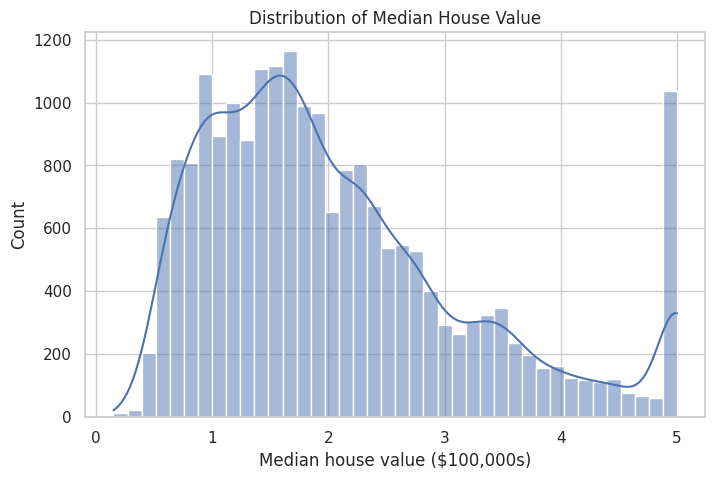

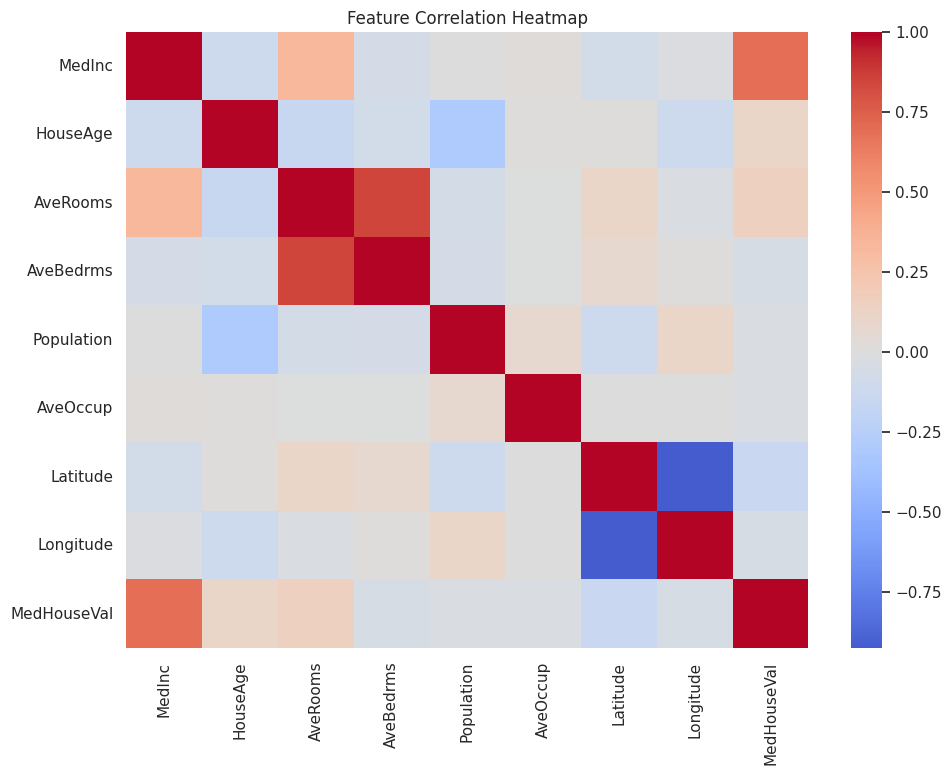

In [4]:
plt.figure(figsize=(8,5))
sns.histplot(df["MedHouseVal"], bins=40, kde=True)
plt.title("Distribution of Median House Value")
plt.xlabel("Median house value ($100,000s)")
plt.show()

plt.figure(figsize=(11,8))
sns.heatmap(df.corr(numeric_only=True), cmap="coolwarm", center=0)
plt.title("Feature Correlation Heatmap")
plt.show()


## 3. Feature selection discussion

All available predictor columns are used for a baseline model:
- `MedInc`: area median income may capture purchasing power.
- `HouseAge`: housing stock age may relate to value.
- `AveRooms`, `AveBedrms`: average room/bedroom counts describe housing composition.
- `Population`, `AveOccup`: area population and average occupancy describe density.
- `Latitude`, `Longitude`: geographic position captures regional differences.

The target `MedHouseVal` is excluded from the predictors to prevent data leakage.

In [5]:
X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"]
numeric_features = X.columns.tolist()

preprocess = ColumnTransformer(
    transformers=[("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_features)]
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print("Training rows:", len(X_train), "| Test rows:", len(X_test))


Training rows: 16512 | Test rows: 4128


## 4. Train Linear Regression and evaluate

MSE penalizes squared errors, RMSE is in the target's units, and R² measures the proportion of variance explained by the model.

In [6]:
linear_model = Pipeline([
    ("preprocess", preprocess),
    ("model", LinearRegression())
])
linear_model.fit(X_train, y_train)
pred = linear_model.predict(X_test)

mse = mean_squared_error(y_test, pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, pred)
print(f"MSE:  {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")


MSE:  0.5559
RMSE: 0.7456
R²:   0.5758


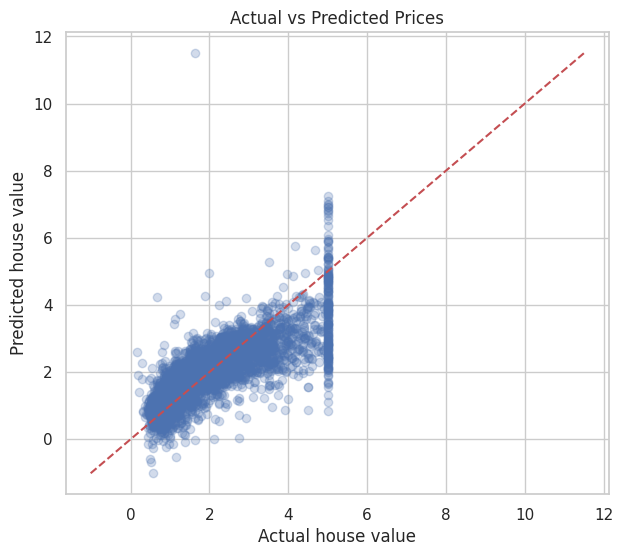

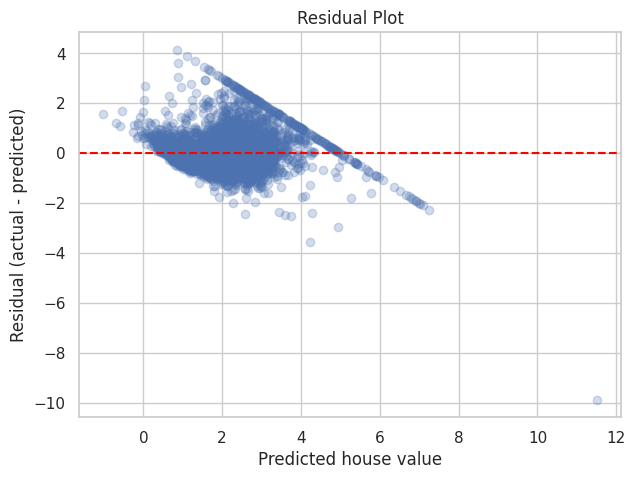

In [7]:
plt.figure(figsize=(7,6))
plt.scatter(y_test, pred, alpha=0.25)
lims = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
plt.plot(lims, lims, "r--")
plt.xlabel("Actual house value")
plt.ylabel("Predicted house value")
plt.title("Actual vs Predicted Prices")
plt.show()

residuals = y_test - pred
plt.figure(figsize=(7,5))
plt.scatter(pred, residuals, alpha=0.25)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted house value")
plt.ylabel("Residual (actual - predicted)")
plt.title("Residual Plot")
plt.show()


## 5. Coefficient analysis

Coefficients are expressed on standardized feature scales because the pipeline standardizes predictors. Positive coefficients increase the prediction while negative coefficients decrease it, holding other features constant.

,Feature,Coefficient
6,Latitude,-0.896929
7,Longitude,-0.869842
0,MedInc,0.854383
3,AveBedrms,0.339259
2,AveRooms,-0.294410
1,HouseAge,0.122546
5,AveOccup,-0.040829
4,Population,-0.002308


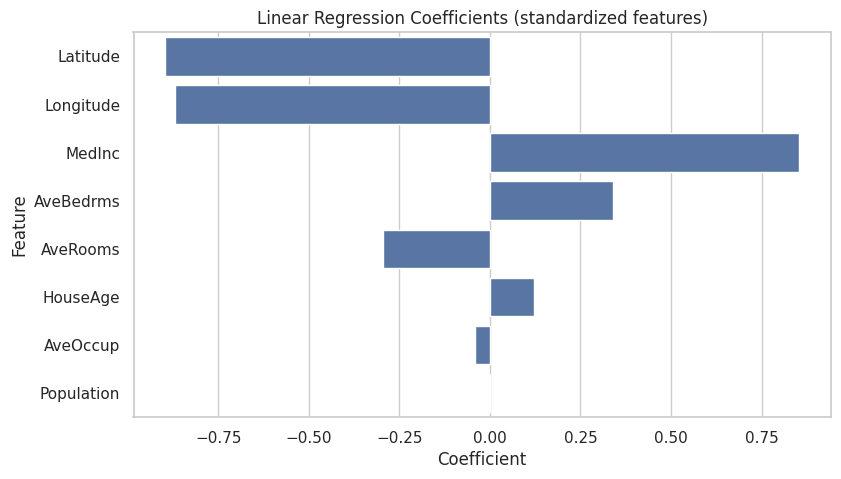

In [8]:
coef = linear_model.named_steps["model"].coef_
coef_df = pd.DataFrame({"Feature": numeric_features, "Coefficient": coef})
coef_df = coef_df.reindex(coef_df["Coefficient"].abs().sort_values(ascending=False).index)
display(coef_df)

plt.figure(figsize=(9,5))
sns.barplot(data=coef_df, x="Coefficient", y="Feature")
plt.title("Linear Regression Coefficients (standardized features)")
plt.show()


## 6. Bonus: Compare Ridge Regression

Ridge adds L2 regularization, which can reduce coefficient magnitude. Compare its test-set metrics with the baseline.

In [9]:
ridge_model = Pipeline([
    ("preprocess", preprocess),
    ("model", Ridge(alpha=1.0))
])
ridge_model.fit(X_train, y_train)
ridge_pred = ridge_model.predict(X_test)

comparison = pd.DataFrame([
    {"Model":"Linear Regression",
     "MSE":mean_squared_error(y_test, pred),
     "RMSE":np.sqrt(mean_squared_error(y_test, pred)),
     "R2":r2_score(y_test, pred)},
    {"Model":"Ridge Regression",
     "MSE":mean_squared_error(y_test, ridge_pred),
     "RMSE":np.sqrt(mean_squared_error(y_test, ridge_pred)),
     "R2":r2_score(y_test, ridge_pred)}
])
display(comparison)


,Model,MSE,RMSE,R2
0,Linear Regression,0.555892,0.745581,0.575788
1,Ridge Regression,0.555855,0.745557,0.575816


## 7. Conclusion

Summarize the observed test metrics, the strongest positive/negative coefficients, and any patterns in the residual plot. Mention that a simple linear model may not capture all geographic and nonlinear effects. This model is for educational analysis, not real-world valuation.